# Percobaan Naive Bayes pada Ulasan Cafind

**Tujuan tugas:** memahami jurnal SVM, KNN, dan Naive Bayes, kemudian mencoba satu
metode pada dataset PBL. Notebook ini mencoba **Multinomial Naive Bayes**.

**Batas klaim:** target `label_proksi` berasal dari rating: 1-2 = negatif,
3 = netral, 4-5 = positif. Model belajar **kelas rating dari teks**. Label tersebut
bukan anotasi sentimen manual dan bukan label sentimen setiap aspek.
Rating hanya dipakai membentuk target; tidak dimasukkan sebagai fitur model.

In [12]:
# Langkah 1 - Import Library

from pathlib import Path
import hashlib
import json
import platform
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, ConfusionMatrixDisplay,
                             f1_score, make_scorer)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
LABELS = ['negatif', 'netral', 'positif']
pd.set_option('display.max_colwidth', 100)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)

Python: 3.11.9 | scikit-learn: 1.9.1


In [13]:
from pathlib import Path
import pandas as pd

# Karena reviews.csv ada di folder yang sama dengan notebook
CURRENT_DIR = Path.cwd()
DATA_PATH = CURRENT_DIR / 'reviews.csv'
OUTPUT_DIR = CURRENT_DIR / 'outputs/naive_bayes_cafind'
RESULT_DIR = OUTPUT_DIR / 'hasil'
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# Membaca dataset
data_raw = pd.read_csv(DATA_PATH)
required = {'review_id', 'cafe_id', 'text', 'rating'}
if not required.issubset(data_raw.columns):
    raise ValueError(f'Kolom wajib yang tidak ditemukan: {required - set(data_raw.columns)}')

print('Sumber:', DATA_PATH)
print('Jumlah baris:', len(data_raw))
display(data_raw[['review_id', 'cafe_id', 'rating', 'text']].head())
display(data_raw['rating'].value_counts(dropna=False).sort_index().rename('jumlah'))

Sumber: d:\Sekolah\SEMESTER 5\Pemmes\244107020175-Mesin-Learning\Klasifikasi\reviews.csv
Jumlah baris: 8010


,review_id,cafe_id,rating,text
0,02d3c3c3-df6f-4533-9785-bfc63996c796,02069a80-3a5e-4a4a-8a48-39cf0b41b534,5.0,"Rekomendasi buat tempat ngopi, pisang goreng nya uwenak, rekomendasi banget"
1,0ad747c7-6b5a-46d7-99a8-03cf9c24404d,02069a80-3a5e-4a4a-8a48-39cf0b41b534,5.0,"Teh susux enak, ngupi sambil melihat lalu lalang"
2,0e704df4-9664-4134-8681-6920d4b07fd9,02069a80-3a5e-4a4a-8a48-39cf0b41b534,5.0,tempat santai dan ena buat nongkrong rame rame
3,289fa293-bb96-4809-adf0-ae48951a3b2a,02069a80-3a5e-4a4a-8a48-39cf0b41b534,5.0,Resmi menamatkan Warkop Djayantie
4,2bba471d-2346-4722-b90b-1aab2cebac93,02069a80-3a5e-4a4a-8a48-39cf0b41b534,5.0,Pisang goreng nya JUARA !\nharus coba pokoknya


rating
1.0     576
2.0     182
3.0     239
4.0     692
5.0    6321
Name: jumlah, dtype: int64

## Persiapan fitur dan target

Naive Bayes memerlukan label. Karena file sumber belum memuat label manual,
pemetaan rating digunakan sebagai **weak label / label proksi** untuk praktikum.
Contoh "kopi enak tetapi wifi lambat" dapat memiliki rating tinggi sekaligus
sentimen negatif pada fasilitas. Karena itu hasil ini belum mengevaluasi ABSA.

Teks dibersihkan secara ringan. Kata negasi dipertahankan. Tidak menggunakan
stopword removal atau stemming pada percobaan awal agar alur mudah dipahami.
Bigram dapat mempelajari pasangan seperti "tidak nyaman", tetapi tidak menjamin
pemahaman negasi atau konteks. Teks yang sama setelah pembersihan hanya disimpan
sekali; semua kelompok teks dengan label rating yang bertentangan dikeluarkan.

In [14]:
# Langkah 3 - Pra Pengolahan Data dan Membuat Label Proksi

def bersihkan_teks(teks):
    teks = unicodedata.normalize('NFKC', str(teks)).lower()
    teks = re.sub(r'https?://\S+|www\.\S+', ' ', teks)
    teks = re.sub(r'[^\w\s]', ' ', teks, flags=re.UNICODE)
    teks = re.sub(r'\d+', ' ', teks)
    return re.sub(r'\s+', ' ', teks).strip()

data = data_raw[['review_id', 'cafe_id', 'text', 'rating']].copy()
data['rating'] = pd.to_numeric(data['rating'], errors='coerce')
data = data.dropna(subset=['review_id', 'cafe_id', 'text', 'rating'])
data = data[data['rating'].isin([1, 2, 3, 4, 5])].copy()
data['text_clean'] = data['text'].map(bersihkan_teks)
data = data[data['text_clean'].str.contains(r'[^\W\d_]', regex=True)].copy()
data['label_proksi'] = np.select(
    [data['rating'] <= 2, data['rating'] == 3],
    ['negatif', 'netral'], default='positif')

label_count = data.groupby('text_clean')['label_proksi'].nunique()
conflicting_texts = label_count[label_count > 1].index
n_conflict = int(data['text_clean'].isin(conflicting_texts).sum())
data = data[~data['text_clean'].isin(conflicting_texts)].copy()
n_before_dedup = len(data)
data = data.drop_duplicates('text_clean', keep='first').reset_index(drop=True)

audit = {'baris_sumber': len(data_raw), 'baris_konflik_label_dikeluarkan': n_conflict,
         'baris_duplikat_dikeluarkan': n_before_dedup - len(data),
         'baris_akhir': len(data), 'kafe_akhir': data['cafe_id'].nunique()}
display(pd.Series(audit, name='jumlah'))
display(data[['text', 'text_clean', 'rating', 'label_proksi']].head())
assert data['text_clean'].is_unique
assert data['review_id'].is_unique, 'Periksa ID ulasan yang berulang pada CSV sumber.'

baris_sumber                       8010
baris_konflik_label_dikeluarkan      58
baris_duplikat_dikeluarkan         1281
baris_akhir                        6646
kafe_akhir                          285
Name: jumlah, dtype: int64

,text,text_clean,rating,label_proksi
0,"Rekomendasi buat tempat ngopi, pisang goreng nya uwenak, rekomendasi banget",rekomendasi buat tempat ngopi pisang goreng nya uwenak rekomendasi banget,5.0,positif
1,"Teh susux enak, ngupi sambil melihat lalu lalang",teh susux enak ngupi sambil melihat lalu lalang,5.0,positif
2,tempat santai dan ena buat nongkrong rame rame,tempat santai dan ena buat nongkrong rame rame,5.0,positif
3,Resmi menamatkan Warkop Djayantie,resmi menamatkan warkop djayantie,5.0,positif
4,Pisang goreng nya JUARA !\nharus coba pokoknya,pisang goreng nya juara harus coba pokoknya,5.0,positif


,jumlah,persentase
label_proksi,,
negatif,648,9.75
netral,196,2.95
positif,5802,87.30


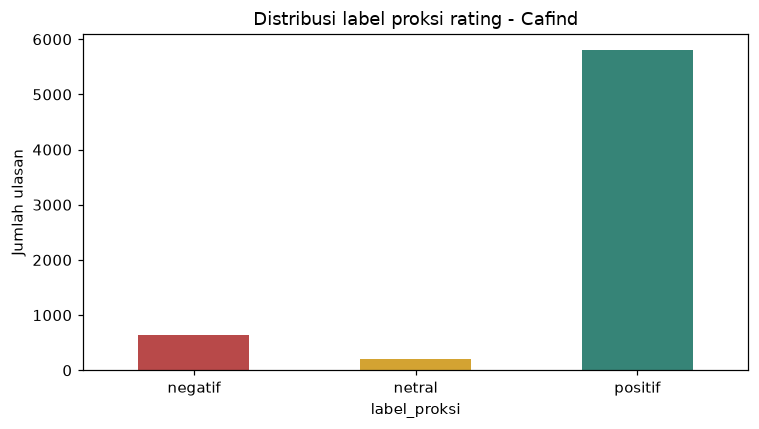

Kelas mayoritas: positif
Proporsi mayoritas keseluruhan: 87.30%


In [15]:
# Langkah 4 - Memeriksa Distribusi Kelas

distribusi = data['label_proksi'].value_counts().reindex(LABELS, fill_value=0)
display(distribusi.rename('jumlah').to_frame().assign(
    persentase=(distribusi / len(data) * 100).round(2)))
ax = distribusi.plot.bar(color=['#b84949', '#d3a332', '#368477'], rot=0,
                        title='Distribusi label proksi rating - Cafind', figsize=(7, 4))
ax.set_ylabel('Jumlah ulasan')
plt.tight_layout()
plt.savefig(RESULT_DIR / 'distribusi_kelas.png', dpi=160)
plt.show()
print('Kelas mayoritas:', distribusi.idxmax())
print('Proporsi mayoritas keseluruhan: {:.2%}'.format(distribusi.max() / len(data)))

## Pembagian data tanpa kebocoran

Data dipisahkan menurut **kafe**: ulasan dari kafe yang sama tidak masuk ke
latih dan uji sekaligus. Tujuannya menguji generalisasi ke kafe yang tidak ada
di data latih. Fold pertama dari pembagian 5-fold dipilih sejak awal sebagai
test set (sekitar 20%; persentase persis dapat berbeda karena ukuran kafe).
Test set tidak dipakai memilih parameter. TF-IDF berada di dalam `Pipeline`,
sehingga kosakata dan IDF dipelajari dari data latih pada setiap fold.
Duplikasi teks persis yang sudah dinormalisasi telah dihilangkan; kemiripan
parafrasa dan penulis yang sama belum diperiksa.

In [16]:
# Langkah 5 - Split Data Training dan Testing

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(
    data['text_clean'], data['label_proksi'], groups=data['cafe_id']))
train = data.iloc[train_idx].copy()
test = data.iloc[test_idx].copy()
X_train, X_test = train['text_clean'], test['text_clean']
y_train, y_test = train['label_proksi'], test['label_proksi']
groups_train = train['cafe_id']

assert set(train['cafe_id']).isdisjoint(test['cafe_id'])
assert set(X_train).isdisjoint(X_test)
assert set(y_train) == set(y_test) == set(LABELS)
split_summary = pd.DataFrame({
    'latih': y_train.value_counts().reindex(LABELS, fill_value=0),
    'uji': y_test.value_counts().reindex(LABELS, fill_value=0)})
display(split_summary)
print(f'Latih: {len(train)} ulasan / {train.cafe_id.nunique()} kafe')
print(f'Uji: {len(test)} ulasan / {test.cafe_id.nunique()} kafe ({len(test)/len(data):.1%})')

,latih,uji
label_proksi,,
negatif,520,128
netral,154,42
positif,4642,1160


Latih: 5316 ulasan / 228 kafe
Uji: 1330 ulasan / 57 kafe (20.0%)


In [17]:
# Langkah 6 - Membuat Model Awal Naive Bayes dan Baseline Mayoritas

model_awal = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 1), min_df=2,
                             max_features=20000, sublinear_tf=True)),
    ('nb', MultinomialNB(alpha=1.0))
])
model_awal.fit(X_train, y_train)

# Baseline tidak belajar isi teks: selalu memprediksi kelas mayoritas data latih.
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(np.zeros((len(train), 1)), y_train)
print('Model awal dan baseline selesai dilatih.')
print('Jumlah fitur model awal:', len(model_awal['tfidf'].vocabulary_))

Model awal dan baseline selesai dilatih.
Jumlah fitur model awal: 4336


In [18]:
# Langkah 7 - Pembuatan Model + Tuning (seperti alur Praktikum4 JS11)

cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(cv.split(X_train, y_train, groups=groups_train))
for fold_train, fold_valid in cv_splits:
    assert set(groups_train.iloc[fold_train]).isdisjoint(groups_train.iloc[fold_valid])
    assert set(y_train.iloc[fold_train]) == set(LABELS)
    assert set(y_train.iloc[fold_valid]) == set(LABELS)

param_grid = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'nb__alpha': [0.1, 1.0, 5.0],
    'nb__fit_prior': [True, False]
}
scorer = make_scorer(f1_score, labels=LABELS, average='macro', zero_division=0)
grid = GridSearchCV(model_awal, param_grid=param_grid, cv=cv_splits,
                    scoring=scorer, n_jobs=1, error_score='raise', refit=True)
grid.fit(X_train, y_train)
model = grid.best_estimator_
print('Parameter terbaik berdasarkan CV data latih:', grid.best_params_)
print('Macro-F1 validasi silang: {:.4f}'.format(grid.best_score_))
cv_results = pd.DataFrame(grid.cv_results_).sort_values('rank_test_score')
display(cv_results[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']].head(6))
# mean_test_score di tabel GridSearchCV = skor fold VALIDASI, bukan test set akhir.

Parameter terbaik berdasarkan CV data latih: {'nb__alpha': 0.1, 'nb__fit_prior': True, 'tfidf__ngram_range': (1, 2)}
Macro-F1 validasi silang: 0.5504


,params,mean_test_score,std_test_score,rank_test_score
1,"{'nb__alpha': 0.1, 'nb__fit_prior': True, 'tfidf__ngram_range': (1, 2)}",0.550379,0.007487,1
3,"{'nb__alpha': 0.1, 'nb__fit_prior': False, 'tfidf__ngram_range': (1, 2)}",0.541607,0.011045,2
2,"{'nb__alpha': 0.1, 'nb__fit_prior': False, 'tfidf__ngram_range': (1, 1)}",0.538706,0.013831,3
0,"{'nb__alpha': 0.1, 'nb__fit_prior': True, 'tfidf__ngram_range': (1, 1)}",0.530305,0.003804,4
6,"{'nb__alpha': 1.0, 'nb__fit_prior': False, 'tfidf__ngram_range': (1, 1)}",0.518400,0.011648,5
7,"{'nb__alpha': 1.0, 'nb__fit_prior': False, 'tfidf__ngram_range': (1, 2)}",0.512509,0.014822,6


`alpha` mengendalikan smoothing: peluang kata tidak langsung nol hanya karena
kata belum muncul pada suatu kelas di data latih. `fit_prior=False` memakai
prior kelas seragam; ini hanya kandidat eksperimen, bukan jaminan memperbaiki
kelas minoritas. Parameter dipilih menggunakan **macro-F1**, agar kelas kecil
mendapat bobot yang sama dengan kelas besar. Tidak melakukan oversampling
pada test set dan tidak menyeimbangkan test set secara buatan.

In [19]:
# Langkah 8 - Cek Performansi pada Test Set yang Sama

pred_baseline = baseline.predict(np.zeros((len(test), 1)))
pred_awal = model_awal.predict(X_test)
yfit = model.predict(X_test)

def hitung_metrik(nama, prediksi):
    return {'model': nama, 'accuracy': accuracy_score(y_test, prediksi),
            'balanced_accuracy': balanced_accuracy_score(y_test, prediksi),
            'macro_f1': f1_score(y_test, prediksi, labels=LABELS, average='macro', zero_division=0),
            'weighted_f1': f1_score(y_test, prediksi, labels=LABELS, average='weighted', zero_division=0)}

hasil = pd.DataFrame([
    hitung_metrik('Baseline mayoritas', pred_baseline),
    hitung_metrik('MultinomialNB awal', pred_awal),
    hitung_metrik('MultinomialNB tuning CV', yfit)])
display(hasil.round(4))
print(classification_report(y_test, yfit, labels=LABELS, digits=4, zero_division=0))
print('Evaluasi terhadap LABEL PROKSI RATING, bukan label sentimen manual.')

,model,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,Baseline mayoritas,0.8722,0.3333,0.3106,0.8126
1,MultinomialNB awal,0.8902,0.3982,0.4207,0.8520
2,MultinomialNB tuning CV,0.9173,0.5267,0.5372,0.8995


              precision    recall  f1-score   support

     negatif     0.7238    0.5938    0.6524       128
      netral     0.0000    0.0000    0.0000        42
     positif     0.9339    0.9862    0.9593      1160

    accuracy                         0.9173      1330
   macro avg     0.5526    0.5267    0.5372      1330
weighted avg     0.8842    0.9173    0.8995      1330

Evaluasi terhadap LABEL PROKSI RATING, bukan label sentimen manual.


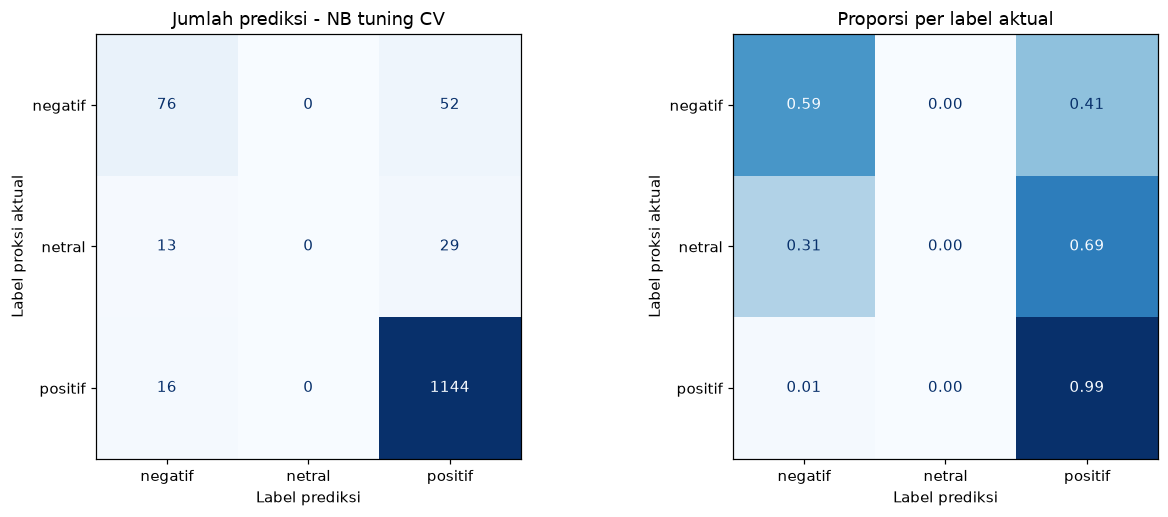

In [20]:
# Langkah 9 - Membuat Confusion Matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay.from_predictions(
    y_test, yfit, labels=LABELS, ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Jumlah prediksi - NB tuning CV')
ConfusionMatrixDisplay.from_predictions(
    y_test, yfit, labels=LABELS, normalize='true', values_format='.2f',
    ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title('Proporsi per label aktual')
for ax in axes:
    ax.set_xlabel('Label prediksi')
    ax.set_ylabel('Label proksi aktual')
plt.tight_layout()
plt.savefig(RESULT_DIR / 'confusion_matrix.png', dpi=160)
plt.show()
# Baris = label aktual; kolom = prediksi. Diagonal = prediksi sesuai label proksi.

In [21]:
# Langkah 10 - Melihat Kesalahan Prediksi

prediksi_uji = test[['review_id', 'cafe_id', 'rating', 'text', 'label_proksi']].copy()
prediksi_uji['prediksi_nb'] = yfit
prediksi_uji['sesuai_proksi'] = prediksi_uji['label_proksi'] == prediksi_uji['prediksi_nb']
kesalahan = prediksi_uji[~prediksi_uji['sesuai_proksi']]
print('Jumlah prediksi berbeda dari label proksi:', len(kesalahan))
display(kesalahan[['text', 'rating', 'label_proksi', 'prediksi_nb']].head(12))
print('Baca teksnya: kesalahan model dan ketidaksesuaian rating-teks dapat bercampur.')

Jumlah prediksi berbeda dari label proksi: 110


,text,rating,label_proksi,prediksi_nb
278,Kapan kopi studio 24 buka disurabaya ..\nKalau dimalang selalu mmpir ke kopstud karna harga nya ...,1.0,negatif,positif
282,Resto remek pancong siji ambek kopi siji lumaaaa buangetttt,1.0,negatif,positif
289,"Kerja banyakan guyon, seal gak beres nyampe rumah bocor semua. Kecewaa!!!!",1.0,negatif,positif
415,"Niatt pengen bgt nasi ronda nya karna dulu buka di dket rumah, sekarang lokasinya pindah.\nTapi ...",1.0,negatif,positif
481,Sarapan baru datang lebih dari satu jam meskipun restorannya kosong.,3.0,netral,negatif
488,‼️⚠️⚠️⚠️KERACUNAN MAKANAN!!! MUNTAH DAN DIARE HEBAT SELAMA 2 HARI SETELAH MAKAN KUE COKELAT ‼️‼️...,2.0,negatif,positif
496,"Tempatnya nyaman, cozy, ga terlalu berisik meskipun dipinggir jalan raya yg ramai.\nBbrp menu yg...",3.0,netral,positif
732,"Droom heaven ada apa dg kopimu, kok rasanya air doang. Next time klo cari karyawan dtes dulu ya ...",2.0,negatif,positif
736,"Mungkin over expectation sih, lihat nama menunya yang unik, ala ala hindia Belanda, tapi ternyat...",2.0,negatif,positif
741,Dizsum nya enak banget baru disini lo aku makan bisa nambah capje.nya kok gak seperti yg dulu y...,2.0,negatif,positif


Baca teksnya: kesalahan model dan ketidaksesuaian rating-teks dapat bercampur.


In [22]:
# Langkah 11 - Mencoba Teks Baru (contoh ilustrasi, bukan pengukuran akurasi)

contoh = pd.DataFrame({'text': [
    'kopinya enak tempatnya nyaman dan harga terjangkau',
    'wifi lambat tempat berisik dan harga mahal',
    'lokasi kafe di dekat jalan utama',
    'kopinya enak tetapi wifi lambat dan harganya mahal',
    'tempatnya tidak nyaman',
    'tempatnya nyaman'
]})
contoh['prediksi_nb'] = model.predict(contoh['text'].map(bersihkan_teks))
display(contoh)
print('Satu label per ulasan tidak menunjukkan sentimen setiap aspek.')

,text,prediksi_nb
0,kopinya enak tempatnya nyaman dan harga terjangkau,positif
1,wifi lambat tempat berisik dan harga mahal,positif
2,lokasi kafe di dekat jalan utama,positif
3,kopinya enak tetapi wifi lambat dan harganya mahal,positif
4,tempatnya tidak nyaman,positif
5,tempatnya nyaman,positif


Satu label per ulasan tidak menunjukkan sentimen setiap aspek.


In [23]:
# Langkah 12 - Menyimpan Hasil dan Manifest Eksperimen

hasil.to_csv(RESULT_DIR / 'metrik_test.csv', index=False)
cv_results.to_csv(RESULT_DIR / 'hasil_tuning_cv.csv', index=False)
prediksi_uji.to_csv(RESULT_DIR / 'prediksi_test.csv', index=False)
laporan = pd.DataFrame(classification_report(
    y_test, yfit, labels=LABELS, output_dict=True, zero_division=0)).T
laporan.to_csv(RESULT_DIR / 'classification_report.csv')
split_summary.to_csv(RESULT_DIR / 'distribusi_split.csv')
data[['review_id', 'cafe_id', 'label_proksi']].assign(
    bagian=np.where(data.index.isin(train_idx), 'latih', 'uji')
).to_csv(RESULT_DIR / 'split_manifest.csv', index=False)

manifest = {
    'dataset': str(DATA_PATH),
    'dataset_sha256': hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    'audit': {k: int(v) for k, v in audit.items()},
    'label_source': 'rating: 1-2 negatif, 3 netral, 4-5 positif; bukan anotasi manual',
    'fitur': 'text_clean saja; rating dan metadata tidak menjadi fitur',
    'split': 'fold pertama StratifiedGroupKFold 5 fold berdasarkan cafe_id',
    'random_state': RANDOM_STATE, 'n_train': len(train), 'n_test': len(test),
    'n_cafe_train': train.cafe_id.nunique(), 'n_cafe_test': test.cafe_id.nunique(),
    'cv': '3 fold berdasarkan cafe_id hanya pada data latih',
    'selection_metric': 'macro_f1', 'best_params': grid.best_params_,
    'best_cv_macro_f1': grid.best_score_,
    'versions': {'python': platform.python_version(), 'sklearn': sklearn.__version__,
                 'pandas': pd.__version__, 'numpy': np.__version__}}
(RESULT_DIR / 'manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
print('Hasil tersimpan di:', RESULT_DIR)

Hasil tersimpan di: d:\Sekolah\SEMESTER 5\Pemmes\244107020175-Mesin-Learning\Klasifikasi\outputs\naive_bayes_cafind\hasil


## Pemeriksaan manual selanjutnya

Sel berikut menyiapkan sampel test set untuk anotasi **sentimen keseluruhan**.
Kolom label manual sengaja kosong dan tidak menampilkan rating maupun prediksi
agar tidak mengarahkan penilaian. Sampel diambil per kelas proksi (maksimal 30
per kelas), sehingga bukan sampel acak representatif distribusi asli. Jangan
melaporkan akurasi sampel ini sebagai akurasi seluruh dataset.

Isi `sentimen_manual` dengan `negatif`, `netral`, `positif`, atau `campuran`.
Kategori campuran dipakai untuk menandai batas model satu label, bukan otomatis
dianggap netral. Untuk ABSA dibutuhkan file anotasi terpisah per aspek.
Template yang sudah ada tidak ditimpa saat Run All diulang.

In [24]:
# Langkah 13 - Menyiapkan Template Anotasi Manual

template_path = RESULT_DIR / 'template_anotasi_manual.csv'
if not template_path.exists():
    sampel = pd.concat([
        test[test['label_proksi'] == label].sample(
            n=min(30, int((test['label_proksi'] == label).sum())),
            random_state=RANDOM_STATE)
        for label in LABELS
    ]).sample(frac=1, random_state=RANDOM_STATE)
    template = sampel[['review_id', 'cafe_id', 'text']].copy()
    template['sentimen_manual'] = ''
    template['alasan'] = ''
    template.to_csv(template_path, index=False)
    print('Template baru dibuat:', template_path)
else:
    print('Template yang sudah ada dipertahankan:', template_path)
print('Template belum merupakan hasil evaluasi manual; perlu dibaca dan diisi manusia.')

Template baru dibuat: d:\Sekolah\SEMESTER 5\Pemmes\244107020175-Mesin-Learning\Klasifikasi\outputs\naive_bayes_cafind\hasil\template_anotasi_manual.csv
Template belum merupakan hasil evaluasi manual; perlu dibaca dan diisi manusia.


In [25]:
# Langkah 14 - Kesimpulan Berdasarkan Hasil Run Ini

nb_row = hasil.loc[hasil['model'] == 'MultinomialNB tuning CV'].iloc[0]
base_row = hasil.loc[hasil['model'] == 'Baseline mayoritas'].iloc[0]
delta = nb_row['macro_f1'] - base_row['macro_f1']
print(f'NB tuning CV: accuracy = {nb_row.accuracy:.2%}, macro-F1 = {nb_row.macro_f1:.4f}')
print(f'Baseline: accuracy = {base_row.accuracy:.2%}, macro-F1 = {base_row.macro_f1:.4f}')
print(f'Selisih macro-F1 terhadap baseline = {delta:+.4f}')
print('Parameter dipilih dari CV; test set hanya dipakai untuk evaluasi akhir.')
print('Layak sebagai percobaan awal klasifikasi kelas rating dari teks.')
print('Kelayakan untuk sentimen Cafind perlu label manual; kelayakan ABSA perlu label per aspek.')
print('Skor jurnal tidak dibandingkan langsung karena dataset, bahasa, label, dan split berbeda.')

NB tuning CV: accuracy = 91.73%, macro-F1 = 0.5372
Baseline: accuracy = 87.22%, macro-F1 = 0.3106
Selisih macro-F1 terhadap baseline = +0.2267
Parameter dipilih dari CV; test set hanya dipakai untuk evaluasi akhir.
Layak sebagai percobaan awal klasifikasi kelas rating dari teks.
Kelayakan untuk sentimen Cafind perlu label manual; kelayakan ABSA perlu label per aspek.
Skor jurnal tidak dibandingkan langsung karena dataset, bahasa, label, dan split berbeda.


## Referensi dan hal yang diadaptasi

1. Mustakim & Priyanta (2022), IJCCS 16(2), 113-124,
   https://doi.org/10.22146/ijccs.68903. Menginspirasi perhatian terhadap aspek,
   ketimpangan data, serta pemisahan latih/validasi/uji. Notebook ini belum
   mereplikasi delapan model aspek/sentimen atau oversampling pada paper.
2. Imelda & Kurnianto (2023), RESTI 7(1), 1-6,
   https://doi.org/10.29207/resti.v7i1.4467. Menginspirasi alur TF-IDF + Naive Bayes
   dan pembacaan confusion matrix. Notebook ini memakai pembagian kafe dan CV,
   bukan pembagian manual 60:40 paper.
3. Patil et al. (2024), Procedia Computer Science 235, 3246-3256,
   https://doi.org/10.1016/j.procs.2024.04.307. Menginspirasi pemakaian
   MultinomialNB untuk ulasan kuliner dan tuning alpha. Notebook ini tidak
   mereplikasi CNN/Bi-LSTM dan tidak menguji SVM/KNN.